# 03 — Business Recommendations

### Background
The company needs to identify customers at risk of churn to develop more targeted retention strategies. In the previous stage, the XGBoost model was used to predict customer churn probabilities. These predictions were then grouped into three risk categories: Low Risk, Medium Risk, and High Risk.

### Objective
To identify customer segments that should be prioritized for retention programs and develop strategic recommendations based on predicted churn probabilities and customer characteristics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_style("white")

In [2]:
df = pd.read_csv("../dataset/customer_predictions_test.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (1409, 26)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,MonthlyChargesGroup,ChurnProbability,PredictedChurn,RiskLevel
0,5178-LMXOP,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,...,Yes,Electronic check,95.10,95.10,1,0-12 Months,Very High,0.923704,1,High
1,1069-XAIEM,Female,1,No,No,1,Yes,Yes,Fiber optic,No,...,Yes,Electronic check,85.05,85.05,1,0-12 Months,High,0.913117,1,High
2,0295-PPHDO,Male,0,No,No,1,Yes,Yes,Fiber optic,No,...,Yes,Electronic check,95.45,95.45,1,0-12 Months,Very High,0.910585,1,High
3,9248-OJYKK,Male,1,No,No,1,Yes,Yes,Fiber optic,No,...,Yes,Electronic check,76.45,76.45,1,0-12 Months,High,0.909627,1,High
4,6861-XWTWQ,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,...,Yes,Electronic check,99.25,665.45,1,0-12 Months,Very High,0.907186,1,High


## 1. Customer Churn Risk Distribution

**Question:** How are customers distributed across the churn risk levels predicted by the machine learning model?

The analysis was conducted using predictions for 1,409 customers in the test set. Customers were classified into three risk categories: **Low, Medium, and High.**

In [3]:
risk_distribution = (
    df["RiskLevel"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
)

risk_percentage = (
    risk_distribution / len(df) * 100
)

risk_summary = pd.DataFrame({
    "TotalCustomers": risk_distribution,
    "Percentage": risk_percentage
})

display(risk_summary.round(2))

,TotalCustomers,Percentage
RiskLevel,,
Low,867,61.53
Medium,422,29.95
High,120,8.52


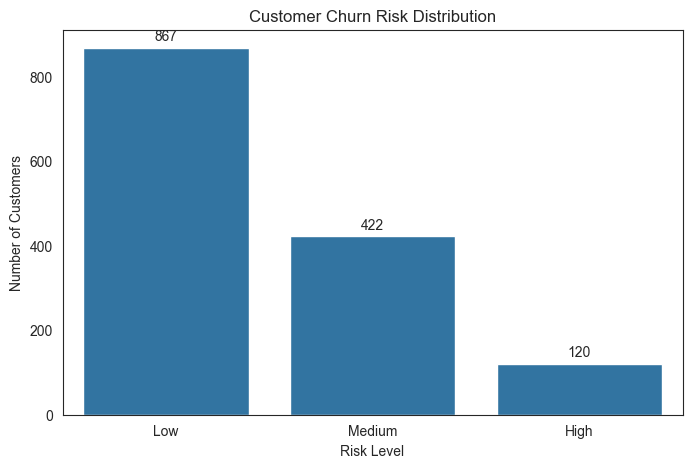

In [4]:
plt.figure(figsize=(8,5))
ax = sns.barplot(x=risk_summary.index, y=risk_summary["TotalCustomers"])
for container in ax.containers: ax.bar_label(container, fmt="%.0f", padding=3)
plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")
plt.grid(False)
plt.show()

Based on the predictions for 1,409 customers, **867 customers (61.53%)** were classified as Low Risk, **422 customers (29.95%)** as Medium Risk, and **120 customers (8.52%)** as High Risk. These findings indicate that most customers have a relatively low predicted probability of churn. Although the High Risk group represents the smallest segment, these customers should be prioritized when developing targeted retention strategies.

## 2. Customer Risk Profile Analysis

**Question:** What are the characteristics of customers across different churn risk levels?

The analysis was conducted to understand differences in customer tenure, monthly charges, predicted churn probability, and contract type across each risk group.

In [5]:
risk_profile = (
    df.groupby("RiskLevel", observed=True)
    .agg(
        TotalCustomers=("customerID", "count"),
        AverageTenure=("tenure", "mean"),
        AverageMonthlyCharges=("MonthlyCharges", "mean"),
        AverageChurnProbability=("ChurnProbability", "mean")
    )
    .round(2)
)

display(risk_profile)

,TotalCustomers,AverageTenure,AverageMonthlyCharges,AverageChurnProbability
RiskLevel,,,,
High,120,4.25,80.74,0.80
Low,867,42.48,57.79,0.09
Medium,422,18.07,72.29,0.48


In [6]:
contract_risk = pd.crosstab(
    df["Contract"],
    df["RiskLevel"],
    normalize="index"
) * 100

display(contract_risk.round(2))

RiskLevel,High,Low,Medium
Contract,,,
Month-to-month,15.52,31.44,53.04
One year,0.00,96.00,4.00
Two year,0.00,100.00,0.00


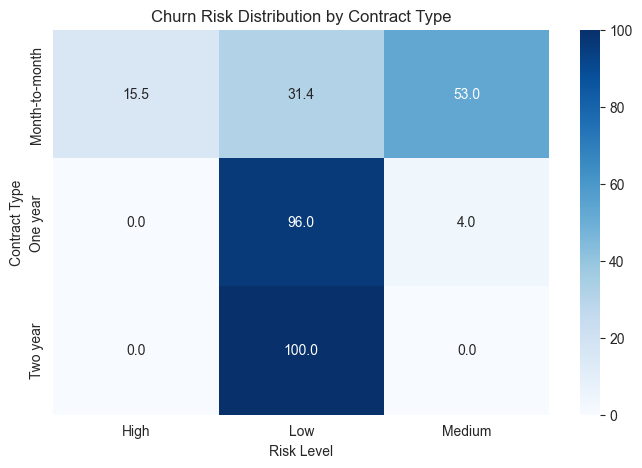

In [7]:
plt.figure(figsize=(8,5))
sns.heatmap(
    contract_risk,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)
plt.title("Churn Risk Distribution by Contract Type")
plt.xlabel("Risk Level")
plt.ylabel("Contract Type")
plt.show()

The analysis shows that customers in the **High Risk** category tend to have shorter subscription periods and higher monthly charges. Additionally, all **120 High Risk customers** in the test set have **Month-to-month** contracts. These findings suggest that customers with monthly contracts should be prioritized when developing targeted retention strategies.

## 3. Retention Strategy Recommendations

**Question:** What retention strategies can be recommended based on customer churn risk levels?

Retention strategies were developed based on three risk categories to help the company prioritize customer retention efforts.

In [8]:
strategy_mapping = {
    "High": "Offer Long-Term Contract Incentive",
    "Medium": "Customer Engagement and Loyalty Program",
    "Low": "Maintain Regular Customer Service"
}

df["RetentionStrategy"] = (
    df["RiskLevel"].map(strategy_mapping)
)

In [9]:
priority_mapping = {
    "High": "Priority 1",
    "Medium": "Priority 2",
    "Low": "Priority 3"
}

df["RetentionPriority"] = (
    df["RiskLevel"].map(priority_mapping)
)

In [10]:
retention_table = df[[
    "customerID",
    "Contract",
    "tenure",
    "MonthlyCharges",
    "InternetService",
    "ChurnProbability",
    "RiskLevel",
    "RetentionPriority",
    "RetentionStrategy"
]].sort_values(
    "ChurnProbability",
    ascending=False
)

display(retention_table.head(10))

,customerID,Contract,tenure,MonthlyCharges,InternetService,ChurnProbability,RiskLevel,RetentionPriority,RetentionStrategy
0,5178-LMXOP,Month-to-month,1,95.10,Fiber optic,0.923704,High,Priority 1,Offer Long-Term Contract Incentive
1,1069-XAIEM,Month-to-month,1,85.05,Fiber optic,0.913117,High,Priority 1,Offer Long-Term Contract Incentive
2,0295-PPHDO,Month-to-month,1,95.45,Fiber optic,0.910585,High,Priority 1,Offer Long-Term Contract Incentive
3,9248-OJYKK,Month-to-month,1,76.45,Fiber optic,0.909627,High,Priority 1,Offer Long-Term Contract Incentive
4,6861-XWTWQ,Month-to-month,7,99.25,Fiber optic,0.907186,High,Priority 1,Offer Long-Term Contract Incentive
5,2609-IAICY,Month-to-month,1,77.15,Fiber optic,0.898700,High,Priority 1,Offer Long-Term Contract Incentive
6,6023-YEBUP,Month-to-month,3,100.95,Fiber optic,0.885993,High,Priority 1,Offer Long-Term Contract Incentive
7,0679-IDSTG,Month-to-month,1,69.25,Fiber optic,0.878737,High,Priority 1,Offer Long-Term Contract Incentive
8,8375-DKEBR,Month-to-month,1,69.60,Fiber optic,0.878377,High,Priority 1,Offer Long-Term Contract Incentive
9,6230-BSUXY,Month-to-month,1,85.00,Fiber optic,0.877465,High,Priority 1,Offer Long-Term Contract Incentive


`RetentionPriority` indicates the priority level of customers in the retention program, while `RetentionStrategy` represents the recommended actions based on their churn risk categories.

- **Priority 1 (High Risk):** Offer incentives for long-term contracts.
- **Priority 2 (Medium Risk):** Implement loyalty programs and increase customer engagement.
- **Priority 3 (Low Risk):** Maintain regular customer service and support.

## 4. Retention Strategy Distribution

**Question:** Which retention strategy is most frequently recommended based on the customer segmentation results?

In [11]:
strategy_distribution = (
    df["RetentionStrategy"]
    .value_counts()
    .reset_index()
)

strategy_distribution.columns = [
    "RetentionStrategy",
    "TotalCustomers"
]

display(strategy_distribution)

,RetentionStrategy,TotalCustomers
0,Maintain Regular Customer Service,867
1,Customer Engagement and Loyalty Program,422
2,Offer Long-Term Contract Incentive,120


`RetentionStrategy` represents the recommended actions to retain customers based on their churn risk levels. The strategies are divided into three categories:

- **Offer Long-Term Contract Incentive:** Provide incentives or special offers to encourage customers to switch to long-term contracts.
- **Customer Engagement and Loyalty Program:** Increase customer engagement and loyalty through reward programs or special offers.
- **Maintain Regular Customer Service:** Maintain service quality and regular communication to ensure customer satisfaction.

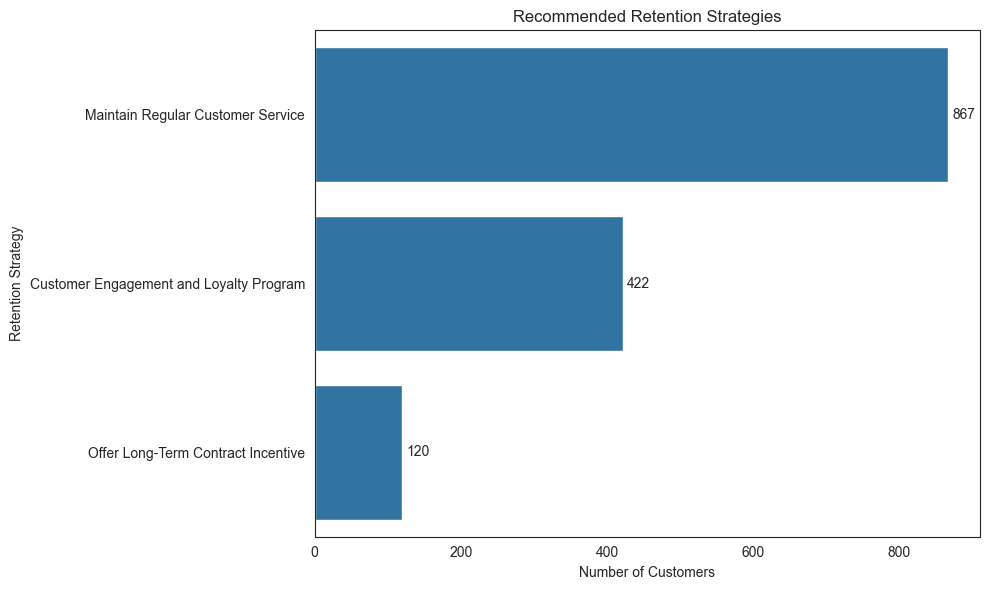

In [12]:
plt.figure(figsize=(10,6))

ax = sns.barplot(
    data=strategy_distribution,
    x="TotalCustomers",
    y="RetentionStrategy"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Recommended Retention Strategies")
plt.xlabel("Number of Customers")
plt.ylabel("Retention Strategy")
plt.grid(False)
plt.tight_layout()
plt.show()

**Maintain Regular Customer Service** was the most frequently recommended strategy, targeting **867 customers (61.53%)**, followed by **Customer Engagement and Loyalty Program** for **422 customers (29.95%)** and **Offer Long-Term Contract Incentive** for **120 customers (8.52%)**. These findings suggest that the company should prioritize more intensive retention efforts for high-risk customers while providing appropriate strategies for other customer segments based on their churn risk levels.

In [13]:
output_path = "../dataset/customer_retention_recommendations.csv"

df.to_csv(
    output_path,
    index=False
)

print("Retention recommendations saved successfully!")
print("File location:", output_path)

Retention recommendations saved successfully!
File location: ../dataset/customer_retention_recommendations.csv


## Business Conclusion

Based on the analysis of 1,409 customers in the test set, the majority were classified as **Low Risk (61.53%)**, followed by **Medium Risk (29.95%)** and **High Risk (8.52%)**. High-risk customers tend to have shorter subscription periods and higher monthly charges, and all of them have **Month-to-month** contracts.

These segmentation results can help the company prioritize retention efforts by offering **long-term contract incentives** to High Risk customers, implementing **loyalty programs** for Medium Risk customers, and maintaining **regular customer service** for Low Risk customers.